In [1]:
import pandas as pd

df = pd.read_csv(
    "../data/raw/PPR-ALL.csv",
    encoding="cp1252",
    low_memory=False
)

print(df.shape)
df.head()

(814413, 9)


,Date of Sale (dd/mm/yyyy),Address,County,Eircode,Price (€),Not Full Market Price,VAT Exclusive,Description of Property,Property Size Description
0,01/01/2010,"5 Braemor Drive, Churchtown, Co.Dublin",Dublin,NaN,"€343,000.00",No,No,Second-Hand Dwelling house /Apartment,NaN
1,03/01/2010,"134 Ashewood Walk, Summerhill Lane, Portlaoise",Laois,NaN,"€185,000.00",No,Yes,New Dwelling house /Apartment,greater than or equal to 38 sq metres and less...
2,04/01/2010,"1 Meadow Avenue, Dundrum, Dublin 14",Dublin,NaN,"€438,500.00",No,No,Second-Hand Dwelling house /Apartment,NaN
3,04/01/2010,"1 The Haven, Mornington",Meath,NaN,"€400,000.00",No,No,Second-Hand Dwelling house /Apartment,NaN
4,04/01/2010,"11 Melville Heights, Kilkenny",Kilkenny,NaN,"€160,000.00",No,No,Second-Hand Dwelling house /Apartment,NaN


   ## Messy data notes

   **Dataset:** 814,413 sales, 9 columns (2010 – present)

   1. **Encoding:** file uses Windows `cp1252` encoding; `latin-1` broke the € symbol.
   2. **Mixed types:** "Property Size Description" has mixed text and empty values. Fixed loading with `low_memory=False`.
   3. **Price is text:** stored as "€343,000.00", needs converting to a number.
   4. **Eircode mostly missing:** empty in early rows (Eircodes only started in 2015).
   5. **Property Size Description mostly missing.**
   6. **Column names are long and messy:** e.g. "Date of Sale (dd/mm/yyyy)", "Price (€)".
   7. **All columns are text:** dates and prices need converting to proper types.
   8. **Eircode:** only 31% present (255,818 / 814,413). Can't rely on it for location.
   9. **Property Size Description:** only 6.5% present. Too sparse to use as a feature.
   10. **No bedrooms / floor area columns:** model must rely on area, date, new vs second-hand.
   11. **County is clean:** exactly 26 counties, no typos. Dublin = 31% of all sales (data is Dublin-heavy).
   12. **Not Full Market Price = Yes:** 41,490 sales (5.1%). Exclude from price analysis.
   13. **VAT Exclusive = Yes:** 143,857 sales (17.7%). Close to but not equal to new builds (146,244). Investigate.
   14. **Description of Property in two languages:** 5 different values for only 2 real categories:
      - Second-hand: "Second-Hand Dwelling house /Apartment" (668,124) + Irish "Teach/Árasán Cónaithe Atháimhe" (45) = **668,169**
      - New: "New Dwelling house /Apartment" (146,240) + Irish "Teach/Árasán Cónaithe Nua" (3) + broken-encoding "Teach/?ras?n C?naithe Nua" (1) = **146,244**
      - Map all to 2 categories: New / Second-Hand.

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 814413 entries, 0 to 814412
Data columns (total 9 columns):
 #   Column                     Non-Null Count   Dtype
---  ------                     --------------   -----
 0   Date of Sale (dd/mm/yyyy)  814413 non-null  str  
 1   Address                    814413 non-null  str  
 2   County                     814413 non-null  str  
 3   Eircode                    255818 non-null  str  
 4   Price (€)                  814413 non-null  str  
 5   Not Full Market Price      814413 non-null  str  
 6   VAT Exclusive              814413 non-null  str  
 7   Description of Property    814413 non-null  str  
 8   Property Size Description  52846 non-null   str  
dtypes: str(9)
memory usage: 55.9 MB


In [3]:
for col in ["County", "Not Full Market Price", "VAT Exclusive", "Description of Property"]:
       print(f"\n--- {col} ---")
       print(df[col].value_counts())


--- County ---
County
Dublin       255242
Cork          90120
Kildare       44496
Galway        39167
Meath         33894
Limerick      29821
Wexford       28485
Wicklow       27542
Louth         22983
Waterford     22286
Kerry         22036
Tipperary     21744
Donegal       21580
Mayo          19390
Clare         18184
Westmeath     15748
Laois         13565
Kilkenny      13154
Cavan         11982
Sligo         11832
Roscommon     11461
Offaly        10429
Carlow         8862
Leitrim        7143
Longford       6856
Monaghan       6411
Name: count, dtype: int64

--- Not Full Market Price ---
Not Full Market Price
No     772923
Yes     41490
Name: count, dtype: int64

--- VAT Exclusive ---
VAT Exclusive
No     670556
Yes    143857
Name: count, dtype: int64

--- Description of Property ---
Description of Property
Second-Hand Dwelling house /Apartment    668124
New Dwelling house /Apartment            146240
Teach/Árasán Cónaithe Atháimhe               45
Teach/Árasán Cónaithe Nua       

In [4]:
price = (
       df["Price (€)"]
       .str.replace("€", "", regex=False)
       .str.replace(",", "", regex=False)
       .astype(float)
   )

pd.set_option("display.float_format", "{:,.0f}".format)

print(price.describe())

count       814,413
mean        323,262
std       1,330,650
min           5,001
25%         145,161
50%         245,100
75%         370,000
max     387,665,198
Name: Price (€), dtype: float64


15. **Prices are heavily skewed:** median €245,100 vs mean €323,262. Use median for reporting, log(price) for modelling.
16. **Extreme high outliers:** max €387.7 million, almost certainly bulk / portfolio sales (e.g. whole apartment blocks), not single homes. Need to detect and exclude.
17. **Possible minimum price cutoff:** min is €5,001. Very cheap sales may be sites, partial shares or errors. Investigate.

In [5]:
df["price_num"] = price

top10 = df.sort_values("price_num", ascending=False).head(10)

top10[["Date of Sale (dd/mm/yyyy)", "Address", "County", "price_num", "Description of Property"]]

,Date of Sale (dd/mm/yyyy),Address,County,price_num,Description of Property
690768,17/10/2024,"24 Tinakilly Grove, Tinakilly Park, Rathnew",Wicklow,"387,665,198",New Dwelling house /Apartment
806861,03/09/2026,"Folio DN247776F, Dublin",Dublin,"251,769,370",New Dwelling house /Apartment
586460,10/02/2023,"O'Devaney Gardens, Arbour Hill, Dublin 7",Dublin,"225,000,000",New Dwelling house /Apartment
771160,27/01/2026,"Montpelier, Dublin 7",Dublin,"225,000,000",New Dwelling house /Apartment
706229,23/12/2024,"Cooper Square, Seven Mills, Clonburris",Dublin,"221,942,731",New Dwelling house /Apartment
797943,15/07/2026,"Part Folio DN244581F comprising, 461 Apartment...",Dublin,"217,488,769",Second-Hand Dwelling house /Apartment
780906,31/03/2026,"BLOCK A B AND C, NEWMARKET YARDS",Dublin,"189,392,526",Second-Hand Dwelling house /Apartment
797944,15/07/2026,"Part of Grand Canal Harbour Apts, 1-150 Block...",Dublin,"186,544,903",Second-Hand Dwelling house /Apartment
431253,17/07/2020,"Apartments 1 - 186 Cheevers Court, Apartments ...",Dublin,"182,378,855",New Dwelling house /Apartment
809489,18/09/2026,"APT 307 BLCOK B1, 2 FISH LANE, DUBLIN LANDINGS",Dublin,"177,056,937",Second-Hand Dwelling house /Apartment


18. **Bulk / portfolio sales:** the top 10 prices (€177m – €388m) are all whole developments, not single homes. Clues: "Folio DN...", "461 Apartments", "Apts 1-150", "Block A B and C", development names with no house number.
19. **Some bulk sales look like single homes:** e.g. "24 Tinakilly Grove" (€387.7m), "APT 307 BLCOK B1" (€177m). Address keywords alone won't catch them; need price rules too.
20. **Address typos exist:** e.g. "BLCOK" instead of "BLOCK".
21. **Data is very recent:** latest sales seen in Sept 2026.

In [6]:
for limit in [1_000_000, 2_000_000, 3_000_000, 5_000_000, 10_000_000]:
       n = (df["price_num"] > limit).sum()
       pct = n / len(df) * 100
       print(f"Over €{limit:,}: {n:,} sales ({pct:.2f}%)")

print()
print("99th percentile:  €{:,.0f}".format(df["price_num"].quantile(0.99)))
print("99.9th percentile: €{:,.0f}".format(df["price_num"].quantile(0.999)))

Over €1,000,000: 16,312 sales (2.00%)
Over €2,000,000: 4,090 sales (0.50%)
Over €3,000,000: 2,054 sales (0.25%)
Over €5,000,000: 1,064 sales (0.13%)
Over €10,000,000: 511 sales (0.06%)

99th percentile:  €1,425,000
99.9th percentile: €6,333,448


22. **High-price distribution:** >€1m: 16,312 (2.0%), >€2m: 4,090 (0.5%), >€3m: 2,054 (0.25%), >€5m: 1,064 (0.13%), >€10m: 511 (0.06%). 99th percentile = €1.43m, 99.9th = €6.33m.
23. **Decision:** don't delete — add an `is_bulk_suspect` flag. Flag if address has bulk keywords (Apartments, Apts, Block, Folio, unit ranges) OR price > €5m. Exclude flagged rows from the model; test sensitivity with €3m vs €5m cutoff.

In [7]:
for limit in [10_000, 20_000, 30_000, 50_000]:
       n = (df["price_num"] < limit).sum()
       pct = n / len(df) * 100
       print(f"Under €{limit:,}: {n:,} sales ({pct:.2f}%)")

print()
cheap = df[df["price_num"] < 20_000]
print("Of sales under €20k, marked 'Not Full Market Price':")
print(cheap["Not Full Market Price"].value_counts())

cheap[["Date of Sale (dd/mm/yyyy)", "Address", "County", "price_num", "Not Full Market Price"]].head(10)

Under €10,000: 1,103 sales (0.14%)
Under €20,000: 4,924 sales (0.60%)
Under €30,000: 11,957 sales (1.47%)
Under €50,000: 34,858 sales (4.28%)

Of sales under €20k, marked 'Not Full Market Price':
Not Full Market Price
No     3877
Yes    1047
Name: count, dtype: int64


,Date of Sale (dd/mm/yyyy),Address,County,price_num,Not Full Market Price
203,08/01/2010,"Number 8, Florence Road, Bray",Wicklow,"16,000",No
204,08/01/2010,"Rathquarter, Sligo",Sligo,"12,000",Yes
344,14/01/2010,"31 dromard road, drimnagh",Dublin,"16,000",Yes
378,14/01/2010,"Srabra, Lough Allen, Boyle",Roscommon,"5,500",Yes
493,18/01/2010,"30 Chapel Grove, Balbriggan, Co Dublin",Dublin,"10,000",Yes
605,20/01/2010,"Ardaneer, Foynes, Co. Limerick",Limerick,"12,500",No
607,20/01/2010,"Caherline, Caherconlish",Limerick,"18,417",No
1002,28/01/2010,"90 Maudlin Court, Thomastown",Kilkenny,"10,000",No
1005,28/01/2010,"97 Great William O'Brien Street, Blackpool, Cork",Cork,"6,000",No
1205,02/02/2010,"20 Royal Canal Court, Ashtown, Dublin 15",Dublin,"17,667",No


24. **Cheap-end distribution:** <€10k: 1,103 (0.14%), <€20k: 4,924 (0.60%), <€30k: 11,957 (1.47%), <€50k: 34,858 (4.28%).
25. **"Not Full Market Price" flag is unreliable:** only 21% of sales under €20k are flagged (1,047 of 4,924). Many unflagged ones look like normal homes at impossible prices (e.g. Florence Road, Bray: €16,000).
26. **Likely partial / share sales:** odd non-round prices (€17,667, €18,417) suggest fractions of a full price (e.g. €53,000 ÷ 3). Some cheap rural sales may be genuine (derelict cottages, sites), especially 2010–2013.
27. **Decision:** add an `is_low_price_suspect` flag for sales < €20,000. Exclude from the model along with bulk suspects and Not Full Market Price = Yes.

In [8]:
df["sale_date"] = pd.to_datetime(df["Date of Sale (dd/mm/yyyy)"], format="%d/%m/%Y")

print("Earliest sale:", df["sale_date"].min().date())
print("Latest sale:  ", df["sale_date"].max().date())
print()
print("Sales per year:")
print(df["sale_date"].dt.year.value_counts().sort_index())

Earliest sale: 2010-01-01
Latest sale:   2026-10-23

Sales per year:
sale_date
2010    21005
2011    18446
2012    25375
2013    30227
2014    43676
2015    49166
2016    49941
2017    55024
2018    57466
2019    59068
2020    49561
2021    59608
2022    62767
2023    63389
2024    61573
2025    62101
2026    46020
Name: count, dtype: int64


In [9]:
print("Sum of yearly counts:", df["sale_date"].dt.year.value_counts().sum())
print("Total rows:          ", len(df))
print("Missing dates:       ", df["sale_date"].isna().sum())

Sum of yearly counts: 814413
Total rows:           814413
Missing dates:        0


28. **Dates:** text in dd/mm/yyyy format. Convert with format="%d/%m/%Y" (Irish day-first format) to avoid day/month mix-ups.
29. **Date range:** 1 Jan 2010 – 23 Oct 2026 (~17 years).
30. **Sales volume tells the market story:** crash low in 2011 (18,446), recovery to 2019 (59,068), COVID dip 2020 (49,561), peak 2023 (63,389).
31. **2026 is incomplete + registration lag:** only 46,020 sales so far. Recent months undercounted because sales take time to be registered. Don't compare 2026 totals with full years; be careful with the most recent months in the model test set.
32. **All dates valid:** yearly counts sum to 814,413 = total rows. 0 missing dates after conversion.

Rows kept: 768,055 of 814,413
sale_date
2010   208,250
2011   175,365
2012   155,000
2013   145,374
2014   152,000
2015   166,000
2016   188,000
2017   215,858
2018   233,480
2019   242,291
2020   246,696
2021   262,115
2022   290,000
2023   310,000
2024   334,802
2025   361,000
2026   378,854
Name: price_num, dtype: float64


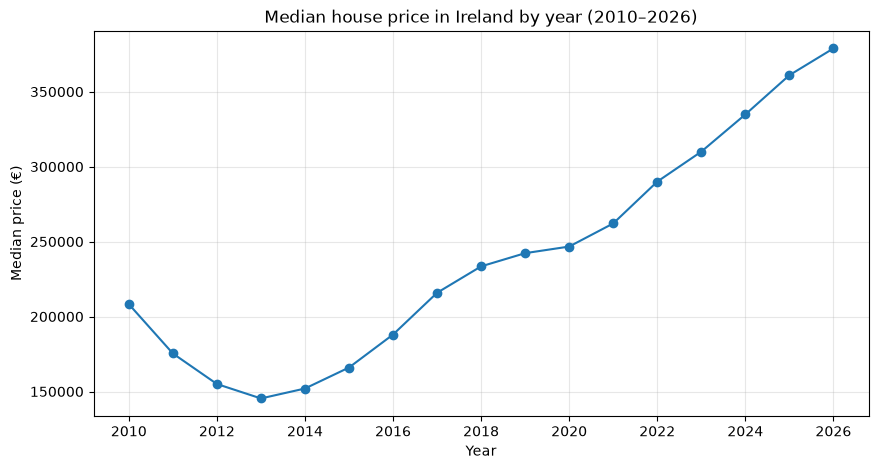

In [10]:
import matplotlib.pyplot as plt

clean = df[
       (df["Not Full Market Price"] == "No")
       & (df["price_num"] >= 20_000)
       & (df["price_num"] <= 5_000_000)
   ]

print(f"Rows kept: {len(clean):,} of {len(df):,}")

median_by_year = clean.groupby(clean["sale_date"].dt.year)["price_num"].median()
print(median_by_year)

median_by_year.plot(marker="o", figsize=(10, 5))
plt.title("Median house price in Ireland by year (2010–2026)")
plt.xlabel("Year")
plt.ylabel("Median price (€)")
plt.grid(True, alpha=0.3)
plt.show()

33. **First finding - median price by year** (excl. Not Full Market Price, <€20k, >€5m → 768,055 rows kept, 5.7% removed):
    - Crash: €208,250 (2010) → €145,374 (2013), -30%
    - Recovery to €246,696 (2020); COVID didn't cause a price drop
    - Now €378,854 (2026): 2.6× the 2013 bottom, +54% since 2020
34. **Caveats:** VAT not yet added to new builds (understates prices). Median is affected by mix of sales (Dublin share, new-build share); next: split by county and new vs second-hand.

region     Dublin  Rest of Ireland  Dublin premium (%)
sale_date                                             
2010      270,000          180,000                  50
2011      245,000          150,000                  63
2012      214,976          130,000                  65
2013      232,500          117,000                  99
2014      257,000          117,500                 119
2015      275,000          130,000                 112
2016      300,000          145,000                 107
2017      327,500          165,000                  98
2018      343,612          182,000                  89
2019      345,000          197,500                  75
2020      359,950          200,000                  80
2021      380,000          220,000                  73
2022      405,000          250,000                  62
2023      418,502          270,000                  55
2024      445,000          290,000                  53
2025      475,000          320,000                  48
2026      

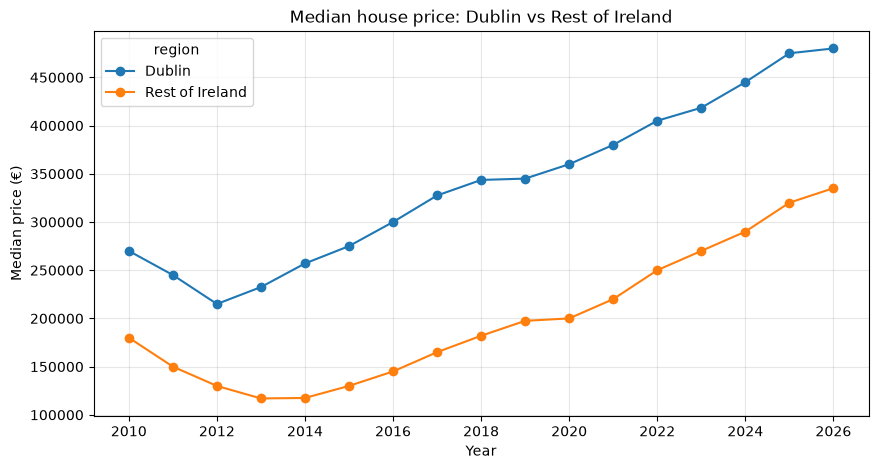

In [11]:
clean = clean.copy()
clean["region"] = clean["County"].where(clean["County"] == "Dublin", "Rest of Ireland")

median_region = (
    clean.groupby([clean["sale_date"].dt.year, "region"])["price_num"]
    .median()
    .unstack()
)

median_region["Dublin premium (%)"] = (
    (median_region["Dublin"] / median_region["Rest of Ireland"] - 1) * 100
).round(0)

print(median_region)

median_region[["Dublin", "Rest of Ireland"]].plot(marker="o", figsize=(10, 5))
plt.title("Median house price: Dublin vs Rest of Ireland")
plt.xlabel("Year")
plt.ylabel("Median price (€)")
plt.grid(True, alpha=0.3)
plt.show()

35. **Dublin vs Rest of Ireland:** Dublin bottomed earlier (2012, €214,976) than the rest (2013–14, €117,000) — recovery started in Dublin and spread outward.
36. **Dublin premium peaked at 119% (2014), now 43% (2026)** — lowest in the dataset. Rest of Ireland grew +186% from its bottom vs Dublin +123%.
37. **Hypotheses (not proven):** commuter-belt spillover, remote work after COVID (premium fell sharply from 2021), Dublin affordability ceiling. Caveat: mix of sales (e.g. new-build share) may affect medians.

           median_2013  median_2025  growth_%
County                                       
Dublin         232,500      475,000       104
Wicklow        190,000      418,943       120
Kildare        175,000      405,286       132
Meath          140,000      376,000       169
Galway         135,250      350,000       159
Cork           145,000      350,000       141
Louth          108,000      330,396       206
Limerick       120,000      317,180       164
Kilkenny       115,000      312,781       172
Westmeath       87,000      308,000       254
Laois           78,000      300,000       285
Waterford       96,000      295,154       207
Clare           98,000      292,000       198
Wexford        100,000      290,000       190
Kerry          115,000      285,000       148
Offaly          85,000      270,000       218
Carlow          96,916      270,000       179
Tipperary       90,000      251,101       179
Sligo           92,000      250,000       172
Cavan           65,000      240,00

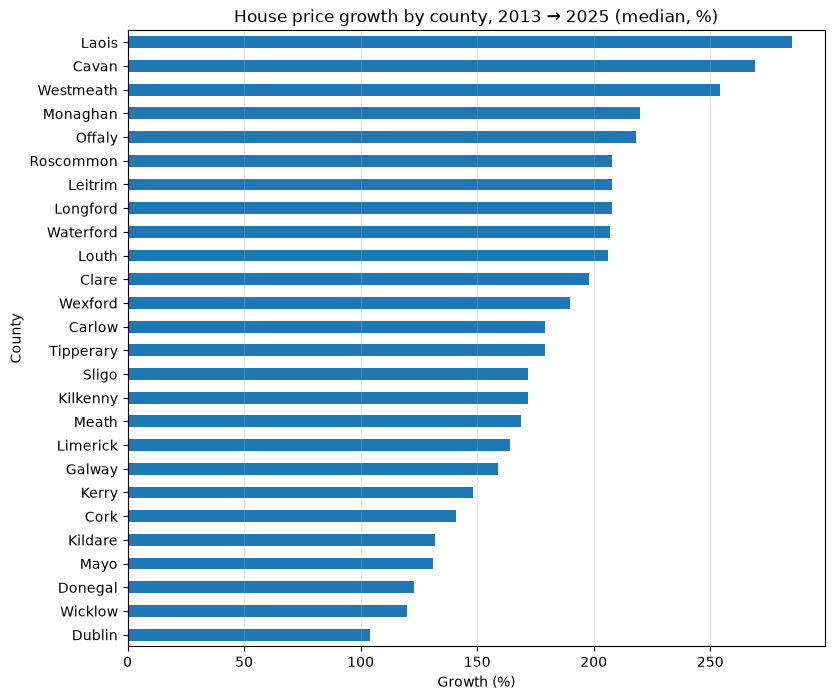

In [12]:
county_year = (
    clean.groupby([clean["sale_date"].dt.year, "County"])["price_num"]
    .median()
    .unstack()
)

county_rank = pd.DataFrame({
    "median_2013": county_year.loc[2013],
    "median_2025": county_year.loc[2025],
})
county_rank["growth_%"] = ((county_rank["median_2025"] / county_rank["median_2013"] - 1) * 100).round(0)
county_rank = county_rank.sort_values("median_2025", ascending=False)

print(county_rank)

county_rank.sort_values("growth_%")["growth_%"].plot(kind="barh", figsize=(9, 8))
plt.title("House price growth by county, 2013 → 2025 (median, %)")
plt.xlabel("Growth (%)")
plt.grid(True, axis="x", alpha=0.3)
plt.show()

38. **County prices 2025:** most expensive = Dublin (€475k), Wicklow (€419k), Kildare (€405k), Meath (€376k). Cheapest = Donegal & Longford (€185k), Roscommon & Leitrim (€200k).
39. **Fastest growth 2013→2025:** Laois +285%, Cavan +269%, Westmeath +254% — the outer commuter ring. Slowest: Dublin +104%, Wicklow +120%, Donegal +123%, Mayo +131%.
40. **"Ripple effect":** growth spread outward from Dublin → inner commuter belt → outer ring. Far north-west (Donegal, Mayo) benefited least.
41. **Caveat — low base effect:** % growth favours counties that started cheap. In euros, Dublin +€242,500 vs Laois +€222,000 — similar. Always show both € and %.
42. **Caveat — small counties have fewer sales:** medians for Leitrim, Longford etc. are noisier.

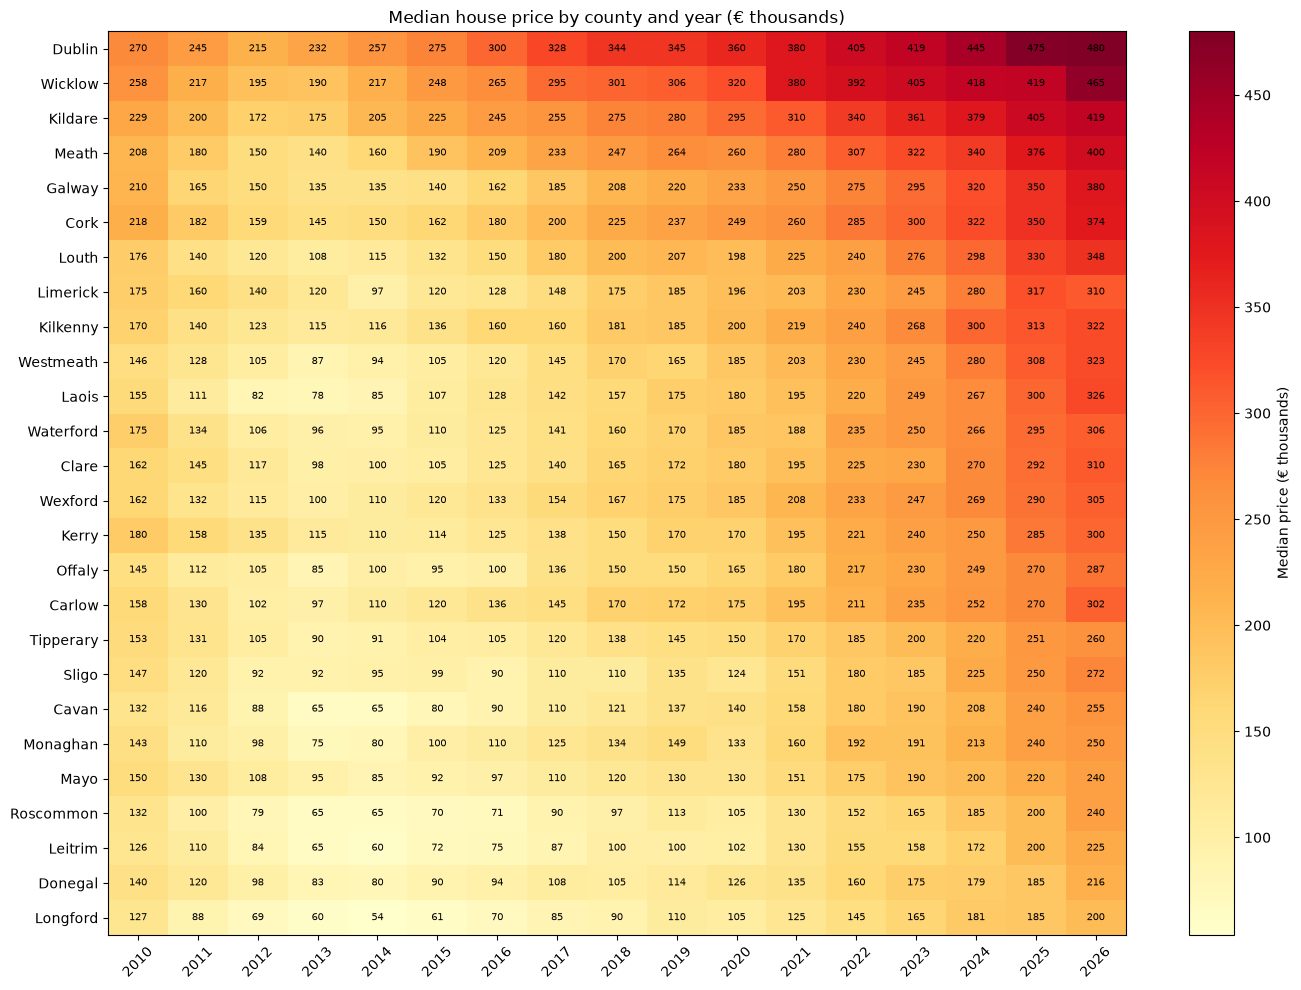

In [13]:
heat = county_year.T / 1000
heat = heat.loc[county_rank.index]

fig, ax = plt.subplots(figsize=(14, 10))
im = ax.imshow(heat, cmap="YlOrRd", aspect="auto")

ax.set_xticks(range(len(heat.columns)))
ax.set_xticklabels(heat.columns, rotation=45)
ax.set_yticks(range(len(heat.index)))
ax.set_yticklabels(heat.index)

for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, f"{heat.iloc[i, j]:.0f}", ha="center", va="center", fontsize=7)

plt.colorbar(im, ax=ax, label="Median price (€ thousands)")
ax.set_title("Median house price by county and year (€ thousands)")
plt.tight_layout()
plt.show()

44. **Heatmap — crash bottom moved outward:** Dublin bottomed 2012, midland counties 2013, west/north-west (Longford, Leitrim, Mayo, Kerry, Limerick, Waterford) 2014. Using 2013 for all counties is a simplification.
45. **Ripple visible:** dark red spreads from Dublin/Wicklow/Kildare (2018) to Laois, Westmeath, Clare, Wexford (2025–26).
46. **Wicklow nearly level with Dublin in 2026:** €465k vs €480k.
47. **Noise in small counties:** e.g. Sligo 2016 dip, Monaghan/Louth 2020 dips, Limerick 2026 lower than 2025 (incomplete year). Treat single-year jumps in small counties with caution.

In [14]:
original_cols = [
    "Date of Sale (dd/mm/yyyy)", "Address", "County", "Eircode", "Price (€)",
    "Not Full Market Price", "VAT Exclusive", "Description of Property",
    "Property Size Description",
]

exact_dupes = df.duplicated(subset=original_cols, keep=False)
print(f"Exact duplicate rows (all columns identical): {exact_dupes.sum():,}")

key_dupes = df.duplicated(subset=["Date of Sale (dd/mm/yyyy)", "Address", "Price (€)"], keep=False)
print(f"Same date + address + price: {key_dupes.sum():,}")

df[key_dupes].sort_values(["Address", "Date of Sale (dd/mm/yyyy)"])[
    ["Date of Sale (dd/mm/yyyy)", "Address", "County", "Price (€)", "Description of Property"]
].head(10)

Exact duplicate rows (all columns identical): 2,066
Same date + address + price: 2,230


,Date of Sale (dd/mm/yyyy),Address,County,Price (€),Description of Property
626779,05/10/2023,"1 2 3 4 5 6 7 8 9 10 11 12 Block 12, & others ...",Louth,"€7,895,885.46",New Dwelling house /Apartment
626780,05/10/2023,"1 2 3 4 5 6 7 8 9 10 11 12 Block 12, & others ...",Louth,"€7,895,885.46",New Dwelling house /Apartment
628266,13/10/2023,"1 ABBEYBROOK GARDENS, KILBEGGAN, WESTMEATH",Westmeath,"€135,000.00",Second-Hand Dwelling house /Apartment
628267,13/10/2023,"1 ABBEYBROOK GARDENS, KILBEGGAN, WESTMEATH",Westmeath,"€135,000.00",Second-Hand Dwelling house /Apartment
246629,16/03/2017,"1 AN BRUACH, BALLYDESMOND, MALLOW",Cork,"€96,500.00",Second-Hand Dwelling house /Apartment
246630,16/03/2017,"1 AN BRUACH, BALLYDESMOND, MALLOW",Cork,"€96,500.00",Second-Hand Dwelling house /Apartment
628575,16/10/2023,"1 BREFFNI HEIGHTS, CARRICK ON SHANNON, LEITRIM",Leitrim,"€26,666.67",Second-Hand Dwelling house /Apartment
628576,16/10/2023,"1 BREFFNI HEIGHTS, CARRICK ON SHANNON, LEITRIM",Leitrim,"€26,666.67",Second-Hand Dwelling house /Apartment
743691,29/08/2025,"1 BROADFORD LAWN, BALLINTEER, DUBLIN 16",Dublin,"€627,000.00",Second-Hand Dwelling house /Apartment
743692,29/08/2025,"1 BROADFORD LAWN, BALLINTEER, DUBLIN 16",Dublin,"€627,000.00",Second-Hand Dwelling house /Apartment


In [15]:
extra_copies = df.duplicated(subset=original_cols, keep="first").sum()
print(f"Extra copies to remove (keep first): {extra_copies:,}")
print(f"Rows after removing: {len(df) - extra_copies:,}")

near = key_dupes & ~exact_dupes
print(f"\nNear-duplicates (same date+address+price, other column differs): {near.sum():,}")
df[near].sort_values(["Address", "Date of Sale (dd/mm/yyyy)"])[
    ["Date of Sale (dd/mm/yyyy)", "Address", "Eircode", "Price (€)", "VAT Exclusive", "Description of Property"]
].head(8)

Extra copies to remove (keep first): 1,092
Rows after removing: 813,321

Near-duplicates (same date+address+price, other column differs): 164


,Date of Sale (dd/mm/yyyy),Address,Eircode,Price (€),VAT Exclusive,Description of Property
535403,27/04/2022,"1 THE GLEBE, STRANORLAR, BALLYBOFEY",F93CE41,"€50,000.00",No,Second-Hand Dwelling house /Apartment
535404,27/04/2022,"1 THE GLEBE, STRANORLAR, BALLYBOFEY",F93V719,"€50,000.00",No,Second-Hand Dwelling house /Apartment
403389,05/12/2019,"11 THE MALTINGS, BONHAM STREET, DUBLIN 8",NaN,"€207,000.00",No,Second-Hand Dwelling house /Apartment
403390,05/12/2019,"11 THE MALTINGS, BONHAM STREET, DUBLIN 8",NaN,"€207,000.00",No,Second-Hand Dwelling house /Apartment
531013,29/03/2022,"12 KILCARAGH VILLAGE, BALLYGUNNER, WATERFORD",X91X20P,"€77,987.65",No,Second-Hand Dwelling house /Apartment
531014,29/03/2022,"12 KILCARAGH VILLAGE, BALLYGUNNER, WATERFORD",X91X20P,"€77,987.65",No,Second-Hand Dwelling house /Apartment
463236,08/02/2021,"12 OLCOVAR, SHANKILL, DUBLIN",NaN,"€45,000.00",No,Second-Hand Dwelling house /Apartment
463237,08/02/2021,"12 OLCOVAR, SHANKILL, DUBLIN",NaN,"€45,000.00",No,New Dwelling house /Apartment


48. **Exact duplicates:** 2,066 rows involved → 1,092 extra copies. Remove (keep first) → 813,321 rows. Duplicates sit next to each other in the file (e.g. rows 626779/626780), suggesting double submission.
49. **Near-duplicates:** 164 rows share date + address + price but differ elsewhere. Mixed causes: different Eircodes (likely genuinely different homes with vague addresses), conflicting New vs Second-Hand labels (e.g. 12 Olcovar, Shankill). Decision: flag as `is_possible_duplicate`, don't remove.
50. **Duplicates overlap with other problems:** e.g. bulk sale "1 2 3 ... Block 12, & others" (€7.9m) and partial share "1 Breffni Heights" (€26,666.67 = €80k ÷ 3).

In [16]:
df["property_type"] = (
    df["Description of Property"]
    .str.contains("New|Nua", regex=True)
    .map({True: "New", False: "Second-Hand"})
)

print("Counts:")
print(pd.crosstab(df["property_type"], df["VAT Exclusive"], margins=True))

print("\nMedian price (€):")
print(pd.crosstab(
    df["property_type"], df["VAT Exclusive"],
    values=df["price_num"], aggfunc="median"
))

Counts:
VAT Exclusive      No     Yes     All
property_type                        
New              2387  143857  146244
Second-Hand    668169       0  668169
All            670556  143857  814413

Median price (€):
VAT Exclusive      No     Yes
property_type                
New           160,000 308,370
Second-Hand   230,000     NaN


51. **VAT is consistent for second-hand:** 0 second-hand sales are VAT-exclusive. All 143,857 VAT-exclusive sales are new builds.
52. **Rule: add VAT back only where VAT Exclusive = Yes** (all new builds). Rate: 13.5% (houses). Since 8 Oct 2025 new apartments are 9%, but the register doesn't separate houses from apartments → use 13.5% for all and state the limitation.
53. **After VAT:** new-build median ≈ €308,370 × 1.135 ≈ €350,000, above second-hand (€230,000), which makes sense.
54. **Odd group — New + VAT Exclusive = No:** 2,387 sales, median only €160,000 (cheaper than second-hand). Unlikely to be normal new-home sales (possibly self-builds, social/affordable transfers, sites, or mislabels). Decision: don't add VAT; flag as `is_new_no_vat`.